In [61]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score , cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
labels = {0: "Stayed", 1: "Churned"}
RANDOM_STATE = 42

STAY, CHURN = "#00C9A7", "#FF4D6D"                   # teal-green / hot pink
PURPLE, BLUE, AMBER, ORANGE = "#7B2FF7", "#00A8FF", "#FFB400", "#FF7A00"
BRIGHT = [STAY, CHURN, PURPLE, BLUE, AMBER, ORANGE]
pal = {"Stayed": STAY, "Churned": CHURN}

In [23]:
df = pd.read_csv("C:\\Users\\ASUS\\Downloads\\archive (10)\\Telco Customer Churn.csv")

In [24]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

In [25]:
df = df.drop(columns=["customerID"])

In [26]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

In [27]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

In [28]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

In [29]:
df["NumServices"] = (df[service_cols] == "Yes").sum(axis=1)

In [30]:
df["AvgChargesPerMonth"] = df["TotalCharges"] / df["tenure"].replace(0, 1)

In [31]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

In [32]:
df["HasSupportBundle"] = ((df["OnlineSecurity"] == "Yes") &
                          (df["TechSupport"] == "Yes")).astype(int)

In [33]:
X = df.drop(columns=["Churn"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

In [34]:
assert "AvgChargesPerMonth" in X_train.columns, "Feature column missing: re-run this whole cell"
print("X_train shape:", X_train.shape)  


X_train shape: (5634, 23)


In [35]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "NumServices", "AvgChargesPerMonth"]
cat_cols = [c for c in X.columns if c not in num_cols]
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

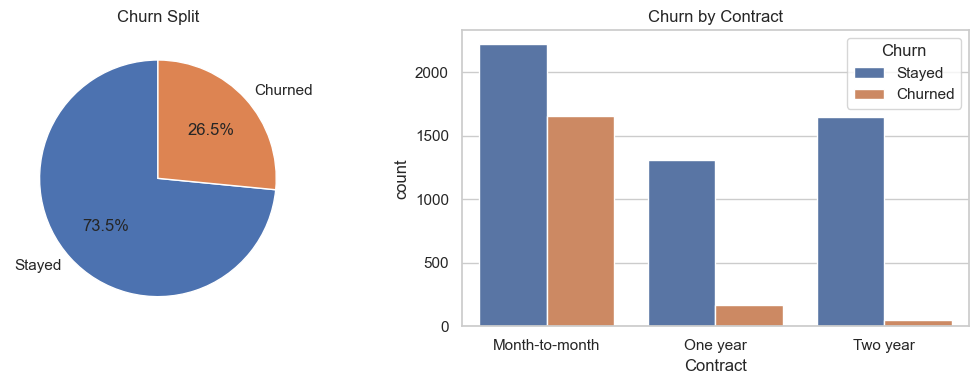

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
c = df["Churn"].map(labels).value_counts()
ax[0].pie(c, labels=c.index, autopct="%1.1f%%", startangle=90)
ax[0].set_title("Churn Split")
sns.countplot(data=df.assign(Churn=df["Churn"].map(labels)), x="Contract", hue="Churn", ax=ax[1])
ax[1].set_title("Churn by Contract")
plt.tight_layout(); plt.show()


In [36]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    results[name] = s.mean()
    print(f"{name:20s} CV ROC-AUC = {s.mean():.4f} (+/- {s.std():.4f})")
best_name = max(results, key=results.get)
print("Best baseline model:", best_name)

LogisticRegression   CV ROC-AUC = 0.8457 (+/- 0.0117)
RandomForest         CV ROC-AUC = 0.8261 (+/- 0.0106)
GradientBoosting     CV ROC-AUC = 0.8471 (+/- 0.0111)
Best baseline model: GradientBoosting


In [62]:
final_model = Pipeline([("prep", preprocess), ("clf", models[best_name])])
final_model.fit(X_train, y_train)
proba = final_model.predict_proba(X_test)[:, 1]
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
p_, r_, t_ = precision_recall_curve(y_train, oof)
thr = t_[np.argmax((2 * p_ * r_ / (p_ + r_ + 1e-9))[:-1])]
pred = (proba >= thr).astype(int)
labels = {0: "Stayed", 1: "Churned"}
print("Threshold:", round(thr, 3))

Threshold: 0.311


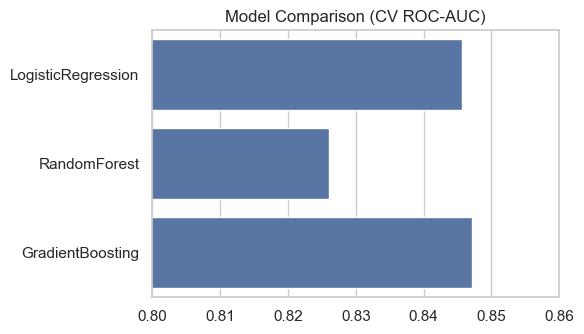

In [63]:
plt.figure(figsize=(6, 3.5))
sns.barplot(x=list(results.values()), y=list(results.keys()))
plt.xlim(0.8, 0.86); plt.title("Model Comparison (CV ROC-AUC)")
plt.tight_layout(); plt.show()

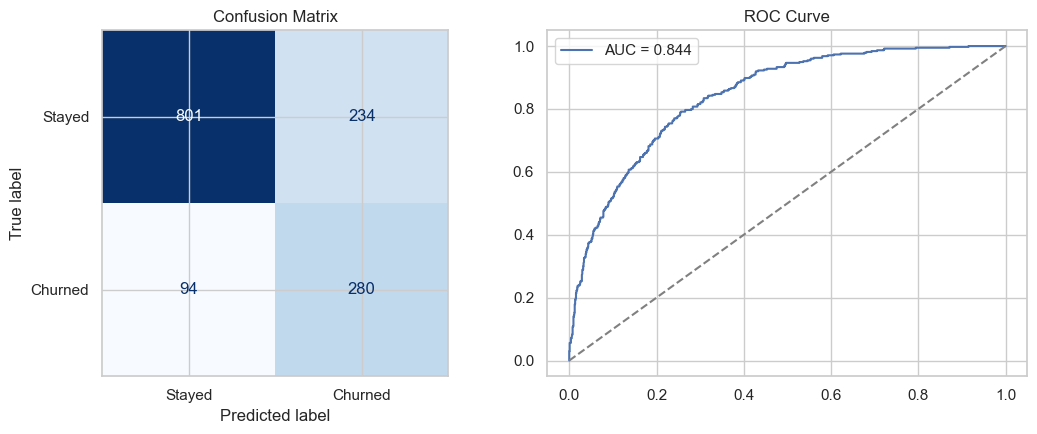

In [64]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Churned"]).plot(
    ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix")
fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
ax[1].plot([0, 1], [0, 1], "--", color="grey"); ax[1].set_title("ROC Curve"); ax[1].legend()
plt.tight_layout(); plt.show()

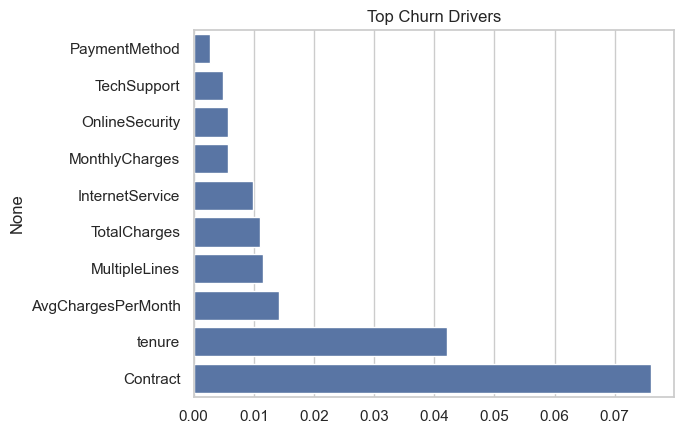

In [65]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(10)
plt.figure(figsize=(7, 4.5))
sns.barplot(x=imp.values, y=imp.index, color="#4c72b0")
plt.title("Top Churn Drivers"); plt.tight_layout(); plt.show()

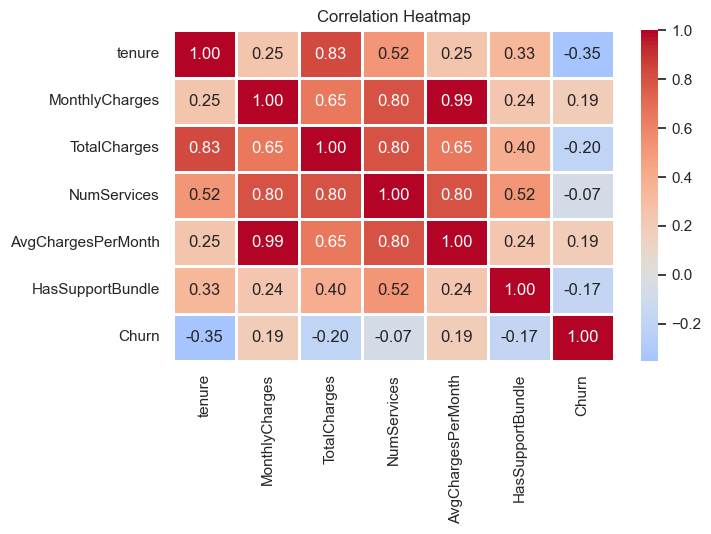

In [66]:
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(df[num_cols + ["HasSupportBundle", "Churn"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=2, linecolor="white")
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

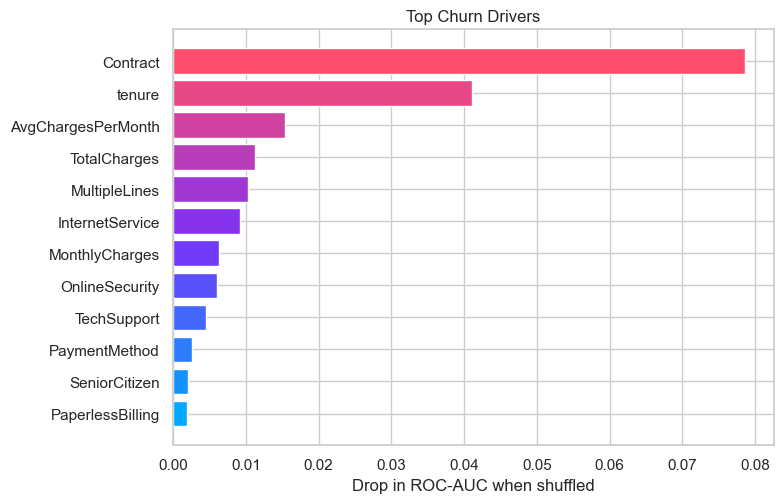

In [58]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(12)[::-1]
plt.figure(figsize=(8, 5.2))
colors = sns.blend_palette([BLUE, PURPLE, CHURN], len(imp))
plt.barh(imp.index, imp.values, color=colors)
plt.title("Top Churn Drivers"); plt.xlabel("Drop in ROC-AUC when shuffled")
plt.tight_layout(); plt.show()

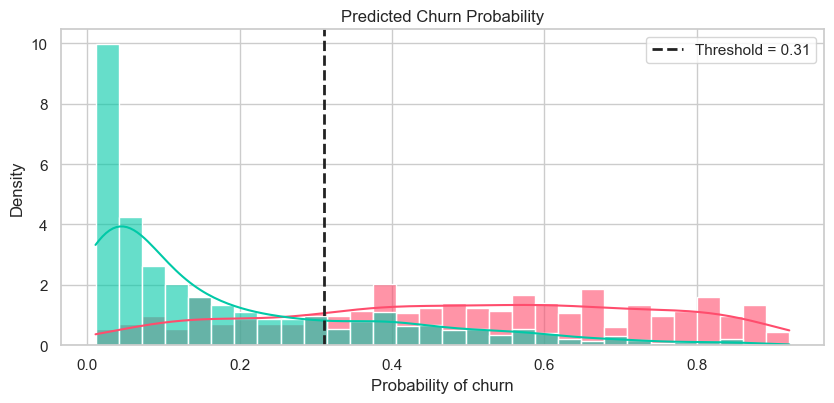

In [67]:
plt.figure(figsize=(8.5, 4.2))
sns.histplot(x=proba, hue=y_test.map(labels).values, bins=30, kde=True, stat="density",
             common_norm=False, palette=pal, alpha=0.6)
plt.axvline(thr, color="#222222", ls="--", lw=2, label=f"Threshold = {thr:.2f}")
plt.title("Predicted Churn Probability"); plt.xlabel("Probability of churn"); plt.legend()
plt.tight_layout(); plt.show()